# scVI integration and annotation 

## Setup

In [1]:
import os
#os.environ["NUMBA_THREADING_LAYER"] = "workqueue"
#os.environ["OMP_NUM_THREADS"] = "1"
#os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"#4 Nina 2 avoid kernel crashing

In [2]:
import pandas as pd
import numpy as np
import scanpy as sc
from collections import defaultdict
import anndata as ad
import gc
import celltypist
from celltypist import models
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgba
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.lines import Line2D
import seaborn as sns
import scvi

os.environ["RPY2_CFFI_MODE"] = "ABI"

/Users/gernotstuhler/miniforge3_arm64/envs/conda_py312/lib/python3.12/site-packages/celltypist/classifier.py:11: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  from scanpy import __version__ as scv


In [3]:
from cap.paths import (project_root, display_path, raw_data_dir,
    figures_dir, dataframe_dir, interim_head_dir, save_dir, model_dir, features_file, data_dir,
    results_dir)
pd.set_option("display.width", 140)
pd.set_option("display.max_rows", 80)

raw_dir    = raw_data_dir()
fig_dir    = figures_dir()
df_dir     = dataframe_dir()
head_dir   = interim_head_dir()
adata_dir  = save_dir()        # data/Adata_Saves
model_path = model_dir()       # data/Scvi_Models
res_dir    = results_dir()     # results/

for d in [head_dir, adata_dir, model_path, fig_dir, df_dir, res_dir]:
    d.mkdir(parents=True, exist_ok=True)
print("project root:", project_root().name)
print("raw counts  :", display_path(raw_dir))

project root: Nowotny_publication
raw counts  : data/raw/raw_counts


In [4]:
from cap.figures import set_style, save_figure, CONDITION_PALETTE, CONDITION_ORDER, CELLTYPE_PALETTE, categorical_palette, sample_order_by_condition
set_style()

In [5]:
condition_rank = {c: i for i, c in enumerate(CONDITION_ORDER)}

In [6]:
#keys: cell types or populations, values: lists of marker genes
marker_genes = {
    "T cells":            ["PTPRC", "CD3D", "CD3E", "CD3G", "TRAC", "IL7R", "CD8A"],
    "NK cells":           ["KLRF1", "NCR1", "FCER1G", "TYROBP", "NKG7", "GNLY", "KLRD1"],
    "B cells":            ["CD79A", "CD79B", "MS4A1", "CD74"],
    "Plasma cells":       ["MZB1", "JCHAIN", "IGHG1", "XBP1", "DERL3"],
    "Macrophages":        ["CD68", "CD14", "ITGAM", "LYZ", "AIF1", "CSF1R"],
    "SPP1+ macrophages":  ["SPP1", "ACP5", "MMP9", "CTSK"],
    "Dendritic cells":    ["ITGAX", "CD1C", "CLEC9A", "CD83"],
    "pDC":                ["IRF7", "IRF8", "TCF4", "GZMB", "LILRA4", "PLAC8"],
    "Mast cells":         ["KIT", "CPA3", "TPSAB1", "TPSB2", "MS4A2"],
    "Fibroblasts":        ["COL1A1", "COL1A2", "COL3A1", "DCN", "LUM", "PDGFRA"],
    "Perivascular":       ["ACTA2", "RGS5", "PDGFRB", "MYH11", "TAGLN"],
    "Endothelial":        ["PECAM1", "VWF", "CDH5", "CLDN5"],
    "Lymphatic":          ["CCL21", "PDPN", "PROX1", "LYVE1"],
    "Epithelial":         ["EPCAM", "KRT8", "KRT18", "KRT19"],
    "Basal":              ["KRT14", "KRT5", "KRT17", "TP63", "MYLK", "OXTR"],
    "Luminal progenitor": ["ALDH1A3", "KIT", "ELF5", "SLPI", "LTF", "KRT15"],
    "Mature luminal":     ["ESR1", "PGR", "FOXA1", "ANKRD30A", "AREG", "TFF1", "GATA3"],
    "Ciliated":           ["FOXJ1", "TPPP3", "CAPS", "FAM183A", "RSPH1", "PIFO"],
    "Cycling":            ["MKI67", "TOP2A", "CCNB1"],
}

In [7]:
s_genes = ["MCM5","PCNA","TYMS","FEN1","MCM2","MCM4","RRM1","UNG","GINS2","MCM6",
           "CDCA7","DTL","PRIM1","UHRF1","HELLS","RFC2","RPA2","NASP","RAD51AP1",
           "GMNN","WDR76","SLBP","CCNE2","UBR7","POLD3","MSH2","ATAD2","RAD51",
           "RRM2","CDC45","CDC6","EXO1","TIPIN","DSCC1","BLM","CASP8AP2","USP1",
           "CLSPN","POLA1","CHAF1B","BRIP1","E2F8"]

In [8]:
g2m_genes = ["HMGB2","CDK1","NUSAP1","UBE2C","BIRC5","TPX2","TOP2A","NDC80","CKS2",
             "NUF2","CKS1B","MKI67","TMPO","CENPF","TACC3","SMC4","CCNB2","CKAP2L",
             "CKAP2","AURKB","BUB1","KIF11","ANP32E","TUBB4B","GTSE1","KIF20B",
             "HJURP","CDCA3","CDC20","TTK","CDC25C","KIF2C","RANGAP1","NCAPD2",
             "DLGAP5","CDCA2","CDCA8","ECT2","KIF23","HMMR","AURKA","PSRC1","ANLN",
             "LBR","CKAP5","CENPE","CTCF","NEK2","G2E3","GAS2L3","CBX5","CENPA"]


# Loading Files

In [9]:
from cap.metadata import load_sample_sheet

samples = load_sample_sheet()# indexed by sample_id
wanted = samples.index[samples["include"]].tolist()
print(f"{len(wanted)} samples expected")

45 samples expected


In [10]:
# per-sample file paths and variable tables only, no expression is read
files = {s: head_dir / f"{s}.h5ad" for s in wanted}

In [ ]:
var_tables = {}
for s, p in files.items():
    a = sc.read_h5ad(p, backed="r")
    var_tables[s] = a.var[["deviance", "mt", "ribo", "hb"]].copy()
    a.file.close()

var_index = var_tables[wanted[0]].index
assert all(t.index.equals(var_index) for t in var_tables.values()), "gene order differs"
deviance = pd.DataFrame({s: t["deviance"] for s, t in var_tables.items()}, index=var_index)

# genes kept in memory: top 5000 by deviance (contains the top 2000 HVGs), markers, key genes
binomial_deviance = deviance.max(axis=1)
exclude = var_tables[wanted[0]][["mt", "ribo", "hb"]].any(axis=1).to_numpy()
exclude |= var_index.isin(s_genes + g2m_genes)
exclude |= var_index.str.match(r"^IG[HKL][VDJC]")
top = binomial_deviance[~exclude].sort_values(ascending=False).index[:5000]
marker_union = {g for genes in marker_genes.values() for g in genes}
keep_genes = set(top) | marker_union | {"ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"}
keep_mask = var_index.isin(list(keep_genes))
print(f"genes kept: {keep_mask.sum():,} of {len(var_index):,}")#1min

## RAM Efficient concatenation

In [ ]:
subset_dir = head_dir / "subset"
subset_dir.mkdir(parents=True, exist_ok=True)
for s in wanted:
    a = sc.read_h5ad(files[s])
    a = a[:, keep_mask].copy()
    a.obsm.clear()
    a.obsp.clear()
    a.varm.clear()
    a.uns = {}
    a.write_h5ad(subset_dir / f"{s}.h5ad")
    del a
    gc.collect()

In [ ]:
(head_dir / "concat_subset.h5ad").unlink(missing_ok=True)

In [ ]:
from anndata.experimental import concat_on_disk

subset_paths = [subset_dir / f"{s}.h5ad" for s in wanted]
concat_on_disk(subset_paths, head_dir / "concat_subset.h5ad",
               join="inner", label="batch", keys=wanted,
               index_unique="-", merge="same")


In [ ]:
adata = sc.read_h5ad(head_dir / "concat_subset.h5ad")
adata.obs["sample"] = adata.obs["batch"]
adata.var["deviance"] = deviance.max(axis=1).reindex(adata.var_names).to_numpy()#7min

In [ ]:
# cross-check first: labels stored in each per-sample file must match the sample sheet
stored = adata.obs.groupby("sample")["condition"].first()
mismatch = stored[stored != samples.loc[stored.index, "condition"]]
if len(mismatch):
    raise ValueError(f"stale condition labels in per-sample files: {mismatch.to_dict()}")

adata.obs["condition"] = adata.obs["sample"].map(samples["condition"])
adata.obs["patient"] = adata.obs["sample"].map(samples["patient"])
assert adata.obs["condition"].notna().all(), "sample without condition"
assert adata.obs["patient"].notna().all(), "sample without patient"
assert set(adata.obs["condition"]) <= set(CONDITION_ORDER), set(adata.obs["condition"])

In [ ]:
d = adata.layers["counts"].data
assert np.allclose(d, np.round(d)), "counts layer is not integer"

In [ ]:
gc.collect()

# HVG and Gene Exclusion

In [ ]:
# gene detection without copying the matrix: count stored non-zeros per gene
detected = adata.layers["counts"].getnnz(axis=0)
adata.var["n_cells"] = detected
print("genes detected in >= 3 cells:", int((detected >= 3).sum()), "of", adata.n_vars)

for g in ["ROR1", "ROR2", "EGFR", "ERBB2", "EPCAM"]:
    assert g in adata.var_names, f"{g} missing from dataset"
    assert adata.var.loc[g, "n_cells"] >= 3, f"{g} detected in fewer than 3 cells"

In [ ]:
# aggregated by the maximum across samples, so a gene deviant in a single subtype is retained
adata.var["binomial_deviance"] = deviance.reindex(adata.var_names).max(axis=1)
assert adata.var["binomial_deviance"].notna().all()

In [ ]:
# ranked after removing genes whose variation is technical or cell-cycle driven,
# and genes detected in fewer than 3 cells (replaces the former filter_genes step)
exclude = adata.var[["mt", "ribo", "hb"]].any(axis=1).to_numpy()
exclude |= adata.var_names.isin(s_genes + g2m_genes)
exclude |= adata.var_names.str.match(r"^IG[HKL][VDJC]")
exclude |= (adata.var["n_cells"] < 3).to_numpy()

In [ ]:
ranked = adata.var.loc[~exclude, "binomial_deviance"].sort_values(ascending=False)

In [ ]:
adata.var["highly_variable"] = adata.var_names.isin(ranked.index[:2000])

assert adata.var["highly_variable"].sum() == 2000

In [ ]:
adata.var["highly_variable"].sum()

## Inspection Before Integration

In [ ]:
hv = adata.var["highly_variable"].to_numpy()
print(f"Shape after HVG subset: {adata.n_obs} cells x {hv.sum()} HVGs")

adata_pre = ad.AnnData(X=adata.layers["log1p"][:, hv],# boolean column selection creates a new matrix
    obs=adata.obs[["sample"]].copy(), var=pd.DataFrame(index=adata.var_names[hv]))

In [ ]:
sc.pp.scale(adata_pre, max_value=10, zero_center=False)
sc.tl.pca(adata_pre, n_comps=20, zero_center=False)

In [ ]:
qc_path = res_dir / "qc_summary.csv"   # written by 000_Papermill (full run only)
assert qc_path.is_file(), "qc_summary.csv missing: run 000_Papermill in full (without --demo)"

qc = pd.read_csv(qc_path)
expected_n = int(samples["include"].sum())   # samples from cell 9
assert len(qc) == expected_n, (len(qc), expected_n)
assert {"sample", "condition", "n_cells_final", "max_pct_mt_retained"} <= set(qc.columns)
print(f"QC summary: {len(qc)} samples")

In [ ]:
print(qc.groupby("condition")[["n_cells_final", "max_pct_mt_retained", "pct_doublets"]]
        .agg(["count", "sum", "median"]).round(1).to_string())

In [ ]:
qc

In [ ]:
# 002_01: cells per sample after QC
fig, ax = plt.subplots(figsize=(12, 3), layout="constrained")
sns.barplot(data=qc, x="sample", y="n_cells_final", hue="condition",
            hue_order=CONDITION_ORDER, palette=CONDITION_PALETTE, dodge=False, ax=ax)
ax.set(xlabel="", ylabel="cells after QC")
ax.tick_params(axis="x", rotation=90, labelsize=6)
save_figure(fig, "002_01_cells_per_sample")
plt.show()

# 002_02: maximum mitochondrial share retained per sample (not the miQC cutoff itself)
fig, ax = plt.subplots(figsize=(12, 3), layout="constrained")
sns.barplot(data=qc, x="sample", y="max_pct_mt_retained", hue="condition",
            hue_order=CONDITION_ORDER, palette=CONDITION_PALETTE, dodge=False, ax=ax)
ax.set(xlabel="", ylabel="max. % MT retained after filtering")
ax.tick_params(axis="x", rotation=90, labelsize=6)
save_figure(fig, "002_02_max_pct_mt_retained_per_sample")
plt.show()

# 002_03: doublets removed per sample
fig, ax = plt.subplots(figsize=(12, 3), layout="constrained")
sns.barplot(data=qc, x="sample", y="pct_doublets", hue="condition",
            hue_order=CONDITION_ORDER, palette=CONDITION_PALETTE, dodge=False, ax=ax)
ax.set(xlabel="", ylabel="doublets removed (%)")
ax.tick_params(axis="x", rotation=90, labelsize=6)
save_figure(fig, "002_03_doublets_per_sample")
plt.show()

# before integration: uncorrected PCA on HVGs (no neighbour graph, no UMAP)
sc.tl.pca(adata_pre, n_comps=20, zero_center=False)   # already computed above, can be omitted
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
sc.pl.pca(adata_pre, color="sample", components=["1,2"], ax=ax, show=False,
          frameon=False, legend_loc="right margin", legend_fontsize=6)
ax.set_title("Before integration (uncorrected PCA on HVGs), coloured by sample")
save_figure(fig, "002_04_pca_before_integration")
plt.show()

In [ ]:
del adata_pre
gc.collect()

# scVI integration

In [ ]:
# immunoglobulin genes are excluded before ranking, so none should be selected
assert not (adata.var_names.str.match(r"^IG[HKL][VDJC]") & adata.var["highly_variable"]).any()

In [ ]:
hv = adata.var["highly_variable"].to_numpy()
adata_scvi = ad.AnnData(
    X=adata.layers["counts"][:, hv],          # raw counts of HVGs, no copy of other layers
    obs=adata.obs[["sample"]].copy(),
    var=pd.DataFrame(index=adata.var_names[hv]),
)

In [ ]:
gc.collect()

In [ ]:
scvi.settings.seed = 0
scvi.settings.num_workers = 0#not 4
scvi.settings.dl_num_workers = 0   # same setting under the name used by newer scvi-tools
scvi.model.SCVI.setup_anndata(adata_scvi, batch_key="sample")
model = scvi.model.SCVI(adata_scvi, n_latent=30, n_layers=2, gene_likelihood="nb")
model.train(max_epochs=400, accelerator="mps", batch_size=1024,
            early_stopping=True, early_stopping_patience=20,
            early_stopping_min_delta=0.5)

In [ ]:
print(f"stopped after {model.history['elbo_train'].shape[0]} epochs")
model.save(str(model_path), overwrite=True)
model.history["elbo_train"].to_csv(df_dir / "scvi_atlas_history.csv")

In [ ]:
adata_scvi.obsm["X_scVI"] = model.get_latent_representation()
assert not np.isnan(adata_scvi.obsm["X_scVI"]).any()


In [ ]:
del model
gc.collect()

In [ ]:
adata.obsm["X_scVI"] = adata_scvi.obsm["X_scVI"]

In [ ]:
del adata_scvi
gc.collect()

# Neighbors and UMAP

In [ ]:
#Neighbors and UMAP on scVI latent space
sc.pp.neighbors(adata, use_rep="X_scVI", n_neighbors=30, random_state=0)
sc.tl.leiden(adata, key_added="scVI_leiden", resolution=1,
             flavor="igraph", n_iterations=2, directed=False, random_state=0)

In [ ]:
gc.collect()

In [ ]:
sc.tl.umap(adata, random_state=0)

In [ ]:
#checking correlation between scVI latent dim 1 and total counts
r = np.corrcoef(adata.obsm["X_scVI"][:, 0], adata.obs["total_counts"])[0, 1]
print(f"scVI latent dim 1 vs total counts: r = {r:+.2f}")   # want near zero

In [ ]:
from sklearn.decomposition import PCA

In [ ]:
# 002_05: scVI latent space, 2-D PCA projection, coloured by condition and by sample
latent = PCA(n_components=2, random_state=0).fit_transform(adata.obsm["X_scVI"])
fig, axes = plt.subplots(1, 2, figsize=(14, 5), layout="constrained")
axis_labels = dict(xlabel="PC1 of scVI latent", ylabel="PC2 of scVI latent")

# condition: fixed order and the shared colours used in all other figures
for cond in CONDITION_ORDER:
    mask = (adata.obs["condition"] == cond).to_numpy()
    if mask.any():
        axes[0].scatter(latent[mask, 0], latent[mask, 1], s=1, alpha=0.5,
                        color=CONDITION_PALETTE[cond], label=cond, rasterized=True)
axes[0].set(title="Condition", **axis_labels)
axes[0].legend(markerscale=5, frameon=False)

# sample: one distinct colour per sample, samples grouped by condition
condition_rank = {c: i for i, c in enumerate(CONDITION_ORDER)}
sample_order = sample_order_by_condition(adata.obs)
sample_colours = sns.color_palette("husl", n_colors=len(sample_order))
sample_values = adata.obs["sample"].to_numpy()
for colour, sid in zip(sample_colours, sample_order):
    mask = sample_values == sid
    axes[1].scatter(latent[mask, 0], latent[mask, 1], s=1, alpha=0.5,
                    color=colour, label=sid, rasterized=True)
axes[1].set(title="Sample", **axis_labels)
axes[1].legend(markerscale=5, fontsize=5, ncol=2, frameon=False,
               loc="upper left", bbox_to_anchor=(1.01, 1))

save_figure(fig, "002_05_scvi_latent_pca")
plt.show()
del latent
gc.collect()

In [ ]:
# Batch mixing: what fraction of each cell's neighbours come from the same sample? 
conn  = adata.obsp["connectivities"].tocsr()
codes = adata.obs["sample"].astype("category").cat.codes.to_numpy()

same       = (codes[conn.indices] == np.repeat(codes, np.diff(conn.indptr)))
n_nb       = np.maximum(np.diff(conn.indptr), 1)
frac_same  = np.add.reduceat(same, conn.indptr[:-1]) / n_nb

p        = adata.obs["sample"].value_counts(normalize=True).to_numpy()
expected = (p ** 2).sum()

print(f"neighbours from the same sample : {frac_same.mean():.3f}")
print(f"expected if perfectly mixed     : {expected:.3f}")
print(f"ratio                           : {frac_same.mean() / expected:.1f}x")


In [ ]:
adata

In [ ]:
adata.write_h5ad(adata_dir / "project_integrated.h5ad", compression="gzip")

In [12]:
# 002_06: integrated UMAP coloured by sample, condition, patient and scVI cluster
SAMPLE_PALETTE = categorical_palette(sample_order_by_condition(adata.obs))
PATIENT_PALETTE = categorical_palette(sorted(adata.obs["patient"].astype(str).unique()))
CLUSTER_PALETTE = categorical_palette(sorted(adata.obs["scVI_leiden"].astype(str).unique(), key=int))

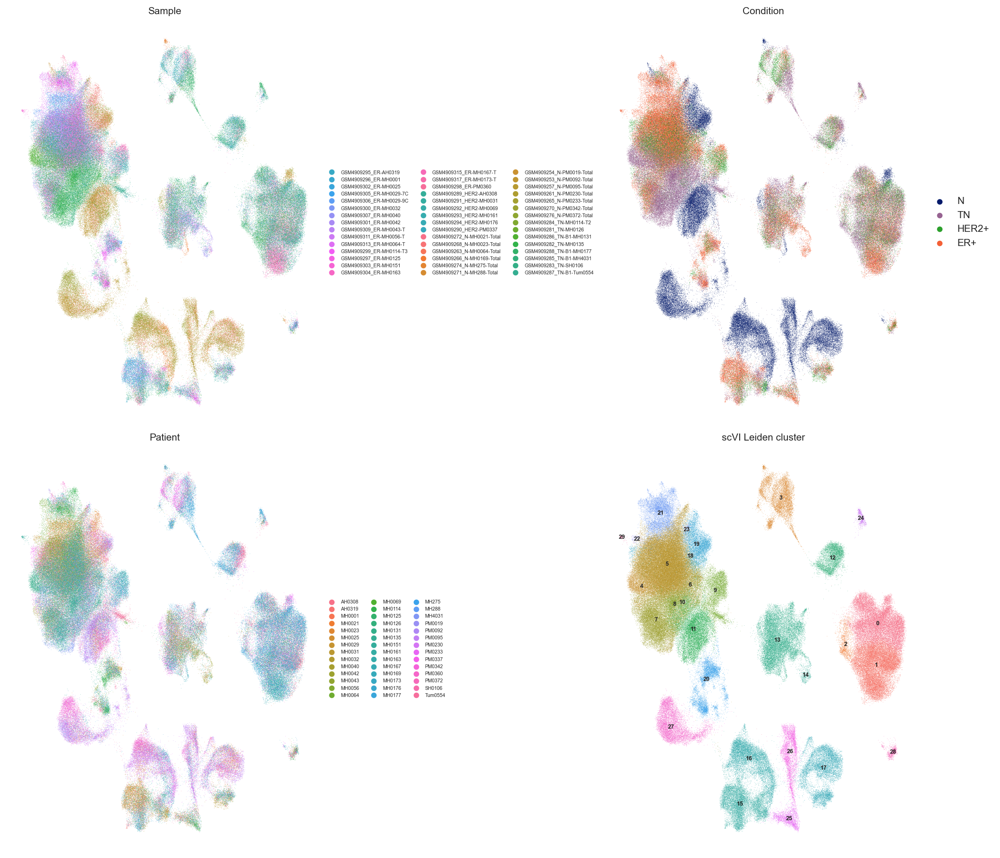

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 12), layout="constrained")
ax = axes.ravel()

sc.pl.umap(adata, color="sample", palette=SAMPLE_PALETTE, ax=ax[0], show=False,
           frameon=False, legend_loc="right margin", legend_fontsize=5, title="Sample")
sc.pl.umap(adata, color="condition", palette=CONDITION_PALETTE, ax=ax[1], show=False,
           frameon=False, legend_loc="right margin", legend_fontsize=10, title="Condition")
sc.pl.umap(adata, color="patient", palette=PATIENT_PALETTE, ax=ax[2], show=False,
           frameon=False, legend_loc="right margin", legend_fontsize=5, title="Patient")
sc.pl.umap(adata, color="scVI_leiden", palette=CLUSTER_PALETTE, ax=ax[3], show=False,
           frameon=False, legend_loc="on data", legend_fontsize=6, title="scVI Leiden cluster")

save_figure(fig, "002_06_umap_sample_condition_patient_leiden")
plt.show()

In [14]:
plt.close("all")   # release all earlier figures
gc.collect()

83

# Celltype Annotation

In [15]:
unexpected = set(adata.obs["condition"].astype(str).unique()) - set(CONDITION_ORDER)
assert not unexpected, f"unexpected condition labels: {unexpected}"
adata.obs["condition"] = pd.Categorical(adata.obs["condition"].astype(str),
                                        categories=CONDITION_ORDER, ordered=True)

In [16]:
print(unexpected)#should be empty set()

set()


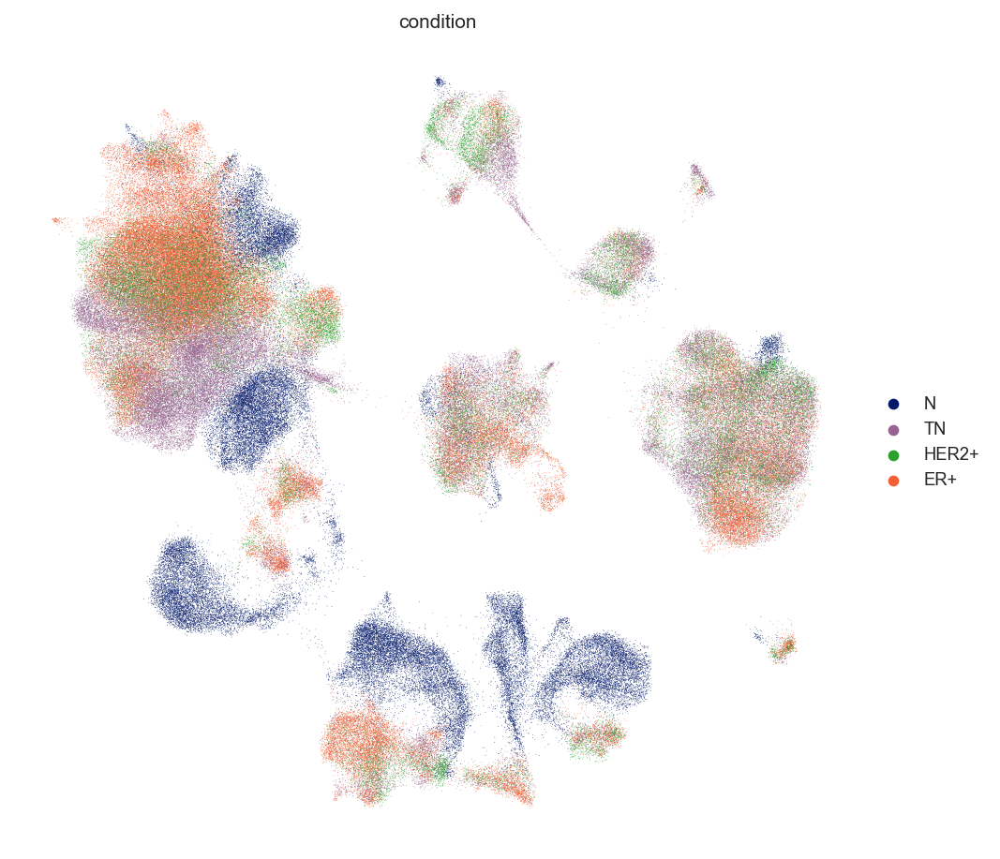

In [17]:
# UMAP coloured by condition
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
sc.pl.umap(adata, color="condition", palette=CONDITION_PALETTE, ax=ax,
           frameon=False, show=False)
save_figure(fig, "2_Cond_ID.png")
plt.show()
plt.close(fig)

In [18]:
adata.obs["sample_short"] = (
    adata.obs["sample"]
    .astype(str)
    .str.strip()
    .str.replace(".h5ad", "", regex=False)
    .str.split("_", n=1).str[-1]
    .str.replace(r"^(TN|ER|HER2|N)-", "", regex=True)
    .astype("category")
)
print("done")


done


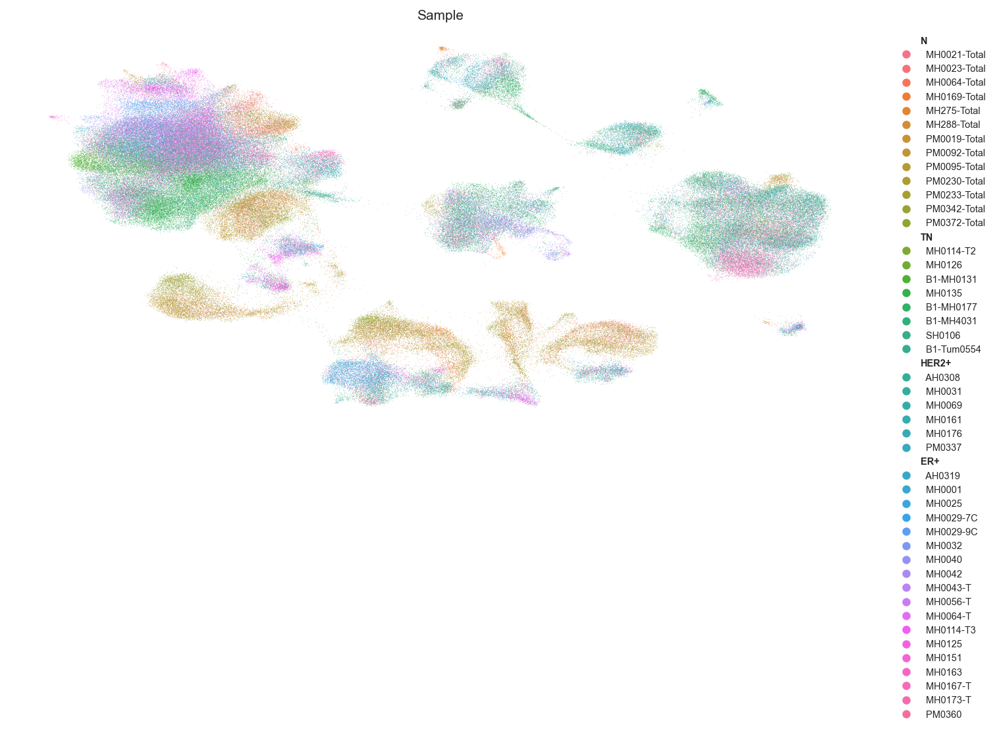

In [19]:
# 002_07: UMAP coloured by sample, legend with short sample names grouped by condition
short_of = dict(zip(adata.obs["sample"], adata.obs["sample_short"]))
cond_of = dict(zip(adata.obs["sample"], adata.obs["condition"]))
assert len(set(short_of.values())) == len(short_of), "sample_short must be unique per sample"

fig, ax = plt.subplots(figsize=(10, 7), layout="constrained")
sc.pl.umap(adata, color="sample", palette=SAMPLE_PALETTE, ax=ax, legend_loc=None,
           show=False, frameon=False, title="Sample")

# grouped legend: one bold header per condition, then its samples in the shared order
handles = []
for condition in CONDITION_ORDER:
    handles.append(Line2D([], [], linestyle="none", label=condition))
    for full in sample_order_by_condition(adata.obs):
        if cond_of[full] == condition:
            handles.append(Line2D([], [], marker="o", linestyle="none", markersize=6,
                                  markerfacecolor=SAMPLE_PALETTE[full], markeredgecolor="none",
                                  label=f"  {short_of[full]}"))

legend = ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc="upper left",
                   frameon=False, fontsize=7, handletextpad=0.5)
for text in legend.get_texts():
    if text.get_text() in CONDITION_ORDER:
        text.set_fontweight("bold")

save_figure(fig, "002_07_umap_sample_short_legend")
plt.show()

In [20]:
gc.collect()

2672

# DEGs

In [21]:
import scipy.sparse as sp
from scipy.stats import rankdata, norm

def wilcoxon_ovr_chunked(X, labels, gene_names, n_genes=50, chunk=100):
    labels = pd.Series(labels).astype(str).to_numpy()
    groups = sorted(pd.unique(labels), key=lambda x: (len(x), x))
    n = X.shape[0]
    gidx = {g: np.where(labels == g)[0] for g in groups}
    codes = pd.Categorical(labels, categories=groups).codes
    onehot = sp.csr_matrix((np.ones(n), (np.arange(n), codes)), shape=(n, len(groups)))
    gene_names = np.asarray(gene_names)
    res = {g: {k: [] for k in ["z", "lfc", "pct"]} for g in groups}
    for start in range(0, X.shape[1], chunk):
        block = X[:, start:start + chunk]
        dense = (block.toarray() if sp.issparse(block) else np.asarray(block)).astype(np.float32, copy=False)
        ranks = rankdata(dense, axis=0).astype(np.float32)      # ranks across all cells
        rank_sums = onehot.T @ ranks
        total = dense.sum(axis=0)
        for gi, g in enumerate(groups):
            n1 = len(gidx[g]); n2 = n - n1
            z = (rank_sums[gi] - n1 * (n + 1) / 2) / np.sqrt(n1 * n2 * (n1 + n2 + 1) / 12.0)
            dg = dense[gidx[g]]
            m_g = dg.mean(axis=0)
            m_r = (total - dg.sum(axis=0)) / max(n2, 1)
            res[g]["z"].append(z)
            res[g]["lfc"].append(np.log2(np.expm1(m_g) + 1e-9) - np.log2(np.expm1(m_r) + 1e-9))
            res[g]["pct"].append((dg > 0).mean(axis=0))
        del dense, ranks, block
        gc.collect()
    out = {}
    for g in groups:
        z = np.concatenate(res[g]["z"]); lfc = np.concatenate(res[g]["lfc"]); pct = np.concatenate(res[g]["pct"])
        p = 2 * norm.sf(np.abs(z))
        order = np.argsort(p)
        padj = np.empty_like(p)
        padj[order] = np.minimum.accumulate((p[order] * len(p) / np.arange(1, len(p) + 1))[::-1])[::-1].clip(max=1)
        o = np.argsort(-z)[:n_genes]
        out[g] = dict(names=gene_names[o], scores=z[o], pvals=p[o], pvals_adj=padj[o],
                      logfoldchanges=lfc[o], pct=pct[o])
    return groups, out

def to_uns(groups, out, groupby, n_genes):
    def rec(key):
        arr = np.zeros(n_genes, dtype=[(str(g), out[g][key].dtype) for g in groups])
        for g in groups:
            arr[str(g)] = out[g][key]
        return arr
    return {"params": {"groupby": groupby, "reference": "rest", "method": "wilcoxon",
                       "use_raw": False, "layer": None, "corr_method": "benjamini-hochberg"},
            "names": rec("names"), "scores": rec("scores"), "pvals": rec("pvals"),
            "pvals_adj": rec("pvals_adj"), "logfoldchanges": rec("logfoldchanges")}

hv_mask = adata.var["highly_variable"].to_numpy()
X_hv = adata.layers["log1p"][:, hv_mask]          # sparse CSR, HVG columns only
if not sp.issparse(X_hv):
    X_hv = sp.csr_matrix(X_hv)

groups, deg_out = wilcoxon_ovr_chunked(
    X_hv, adata.obs["scVI_leiden"].astype(str).to_numpy(),
    adata.var_names[hv_mask], n_genes=50, chunk=100)

adata.uns["rank_genes_groups"] = to_uns(groups, deg_out, "scVI_leiden", 50)

degs = pd.DataFrame({g: deg_out[g]["names"] for g in groups})
degs.to_csv(df_dir / "cluster_degs.csv", index=False)
degs.head(15)

del X_hv, deg_out
gc.collect()

0

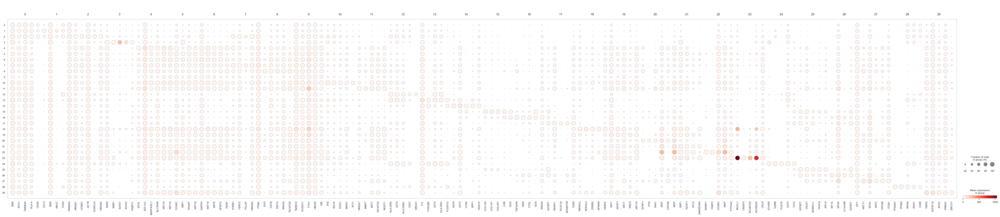

In [22]:
sc.pl.rank_genes_groups_dotplot(adata, n_genes=5, swap_axes=False, dendrogram=False, save="_cluster_degs.png")

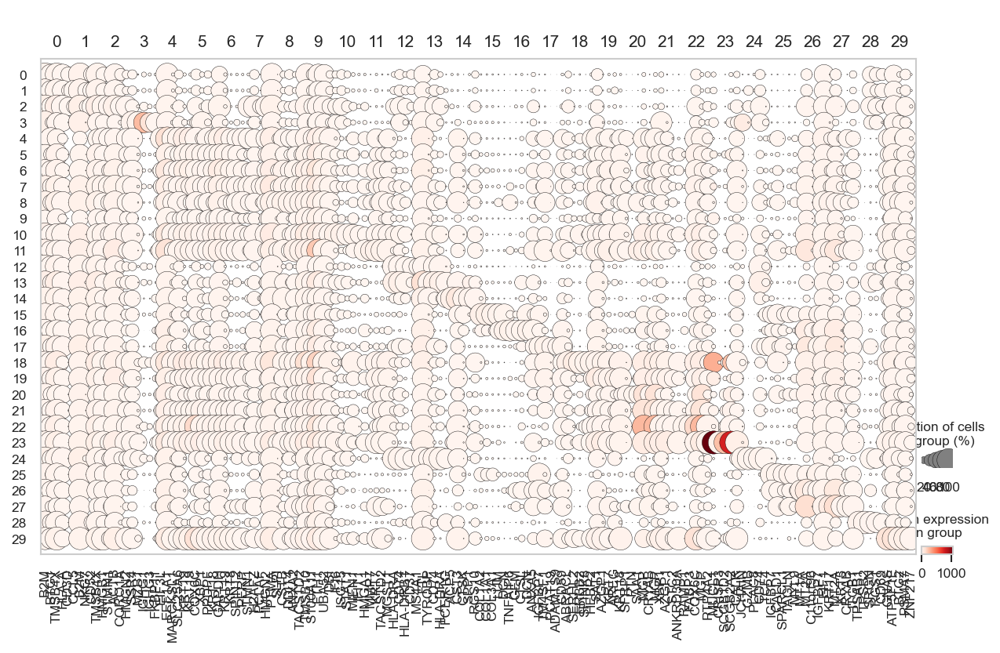

In [23]:
fig, ax = plt.subplots(figsize=(10, 6), layout="constrained")
sc.pl.rank_genes_groups_dotplot(adata, n_genes=5, swap_axes=False, dendrogram=False,
                                ax=ax, show=False)
save_figure(fig, "002_10_degs_dotplot")
plt.show()

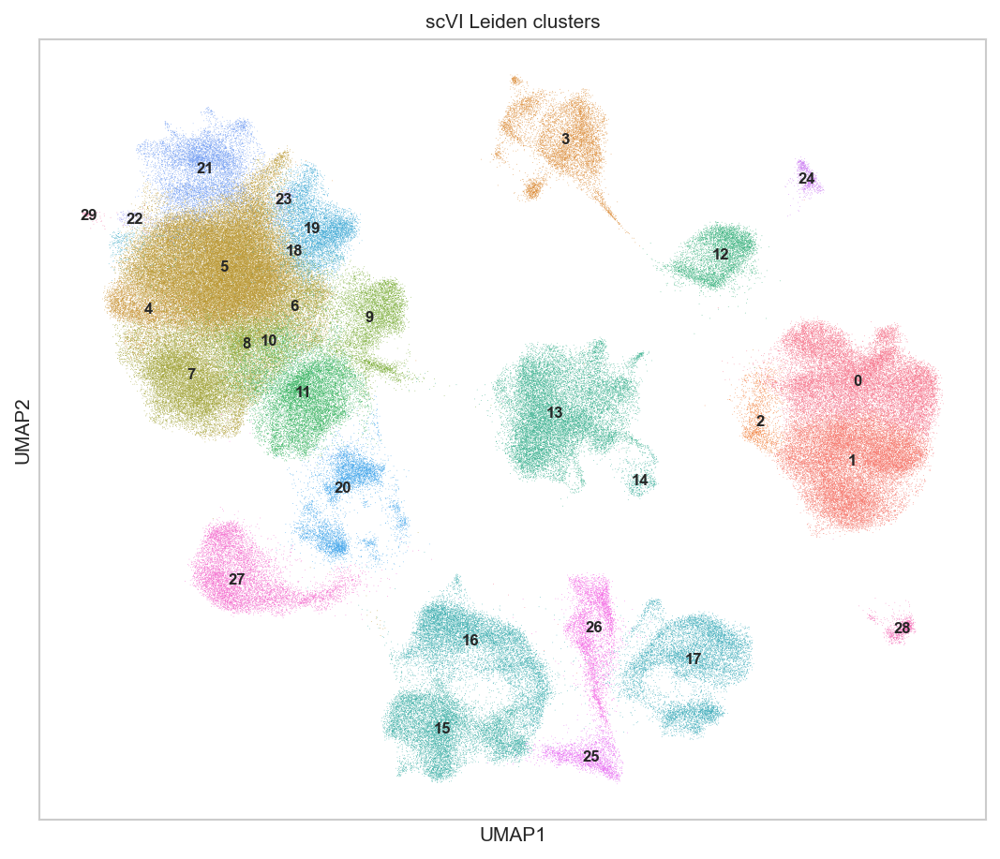

In [24]:
fig, ax = plt.subplots(figsize=(7, 6), layout="constrained")
sc.pl.umap(adata, color="scVI_leiden", palette=CLUSTER_PALETTE, ax=ax,
           legend_loc="on data", legend_fontsize=8, show=False,
           title="scVI Leiden clusters")
save_figure(fig, "002_08_umap_leiden_numbers")
plt.show()

# Basic Marker Genes

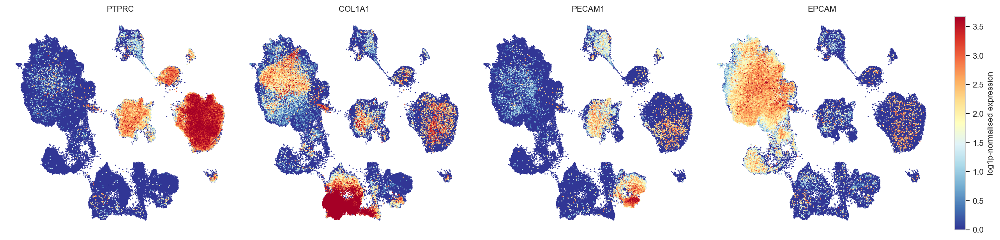

In [25]:
# 002_11: compartment markers on the UMAP, one shared colour scale
basic_marker_genes = ["PTPRC", "COL1A1", "PECAM1", "EPCAM"]

missing = [g for g in basic_marker_genes if g not in adata.var_names]
if missing:
    raise ValueError(f"marker genes not in dataset: {missing}")
# shared colour scale from the log-normalised layer, capped at the 99th percentile
values = np.concatenate([adata[:, g].layers["log1p"].toarray().ravel()
                         for g in basic_marker_genes])
vmax = float(np.percentile(values, 99))

fig, axes = plt.subplots(1, len(basic_marker_genes),
                         figsize=(4 * len(basic_marker_genes) + 1, 4),
                         layout="constrained")
for ax, gene in zip(axes, basic_marker_genes):
    sc.pl.umap(adata, color=gene, layer="log1p", ax=ax, cmap="RdYlBu_r",
               vmin=0, vmax=vmax, size=8, sort_order=True, frameon=False,
               colorbar_loc=None, show=False, title=gene)

# one colourbar for all panels, matching the shared scale
norm = Normalize(vmin=0, vmax=vmax)
mappable = ScalarMappable(norm=norm, cmap="RdYlBu_r")
mappable.set_array([])
cbar = fig.colorbar(mappable, ax=list(axes), location="right", fraction=0.03, pad=0.02)
cbar.set_label("log1p-normalised expression")

save_figure(fig, "002_11_umap_compartment_markers")
plt.show()

In [16]:
# keep only genes present in the dataset, and report what is missing
present = {ct: [g for g in genes if g in adata.var_names] for ct, genes in marker_genes.items()}
absent = {ct: [g for g in genes if g not in adata.var_names] for ct, genes in marker_genes.items()}
print("missing from dataset:", {ct: g for ct, g in absent.items() if g} or "none")
present = {ct: genes for ct, genes in present.items() if genes}

missing from dataset: none


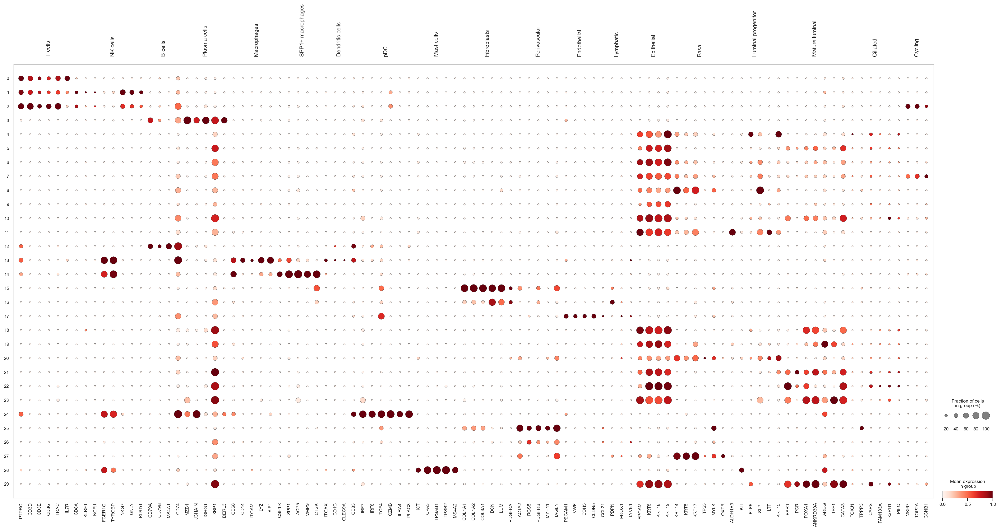

In [27]:
# 002_09: marker dotplot per scVI cluster, grouped by population (staircase)
# standard_scale="var": each gene is scaled to 0-1 across clusters
n_genes = sum(len(genes) for genes in present.values())
n_clusters = adata.obs["scVI_leiden"].nunique()
fig, ax = plt.subplots(figsize=(0.28 * n_genes + 4, 0.45 * n_clusters + 2),
                       layout="constrained")
sc.pl.dotplot(adata, groupby="scVI_leiden", var_names=present, layer="log1p",
              standard_scale="var", dendrogram=False, smallest_dot=10,
              ax=ax, show=False)
save_figure(fig, "002_09_dotplot_markers_by_leiden")
plt.show()

# Celltypist Annotation

### Normalisation

In [28]:
features = pd.read_csv(features_file(), sep="\t", header=None,
                       names=["gene_id", "symbol", "feature_type"])
symbol_to_ensembl = dict(zip(features["symbol"], features["gene_id"]))
print(f"reference: {len(symbol_to_ensembl):,} symbols with Ensembl IDs")
pal_model = models.Model.load(str(data_dir() / "model_from_pal.pkl"))

# all cell keys of the concatenated object, computed once for the barcode check
adata_keys = set(adata.obs_names)

pal_labels, pal_conf = [], []

reference: 33,514 symbols with Ensembl IDs


In [29]:
for i, s in enumerate(wanted, start=1):
    print(f"CellTypist {i}/{len(wanted)}: {s}")

    a = sc.read_h5ad(files[s])                    # full genes, one sample at a time

    # key check first: every barcode of this sample must exist in the concatenated object
    expected = {f"{bc}-{s}" for bc in a.obs_names}
    assert expected <= adata_keys, f"barcode keys for {s} not found in adata"

    b = ad.AnnData(X=a.layers["counts"].tocsr().astype(np.float32),
                   obs=pd.DataFrame(index=a.obs_names),
                   var=pd.DataFrame(index=a.var_names))
    sc.pp.normalize_total(b, target_sum=1e4)
    sc.pp.log1p(b)

    ens = pd.Series(a.var_names.map(symbol_to_ensembl), index=a.var_names)
    keep = ens.notna().to_numpy()
    if i == 1:
        print(f"  {s}: {keep.sum():,} of {len(keep):,} genes mapped to Ensembl IDs")

    b = b[:, keep].copy()
    b.var_names = ens[keep].astype(str).to_numpy()
    b.var_names_make_unique()

    pred = celltypist.annotate(b, model=pal_model, majority_voting=False)
    keys = [f"{bc}-{s}" for bc in pred.predicted_labels.index]   # matches index_unique="-"
    pal_labels.append(pd.Series(pred.predicted_labels["predicted_labels"].to_numpy(), index=keys))
    pal_conf.append(pd.Series(pred.probability_matrix.max(axis=1).to_numpy(), index=keys))

    del a, b, pred, ens, keep, expected
    gc.collect()

adata.obs["celltypist_pal_label"] = pd.concat(pal_labels).reindex(adata.obs_names).to_numpy()
adata.obs["celltypist_pal_conf"] = pd.concat(pal_conf).reindex(adata.obs_names).to_numpy()
assert adata.obs["celltypist_pal_label"].notna().all(), "cells without CellTypist label"
print(f"labelled {adata.n_obs:,} cells")

CellTypist 1/45: GSM4909295_ER-AH0319


🔬 Input data has 2863 cells and 33514 genes
🔗 Matching reference genes in the model
🧬 1395 features used for prediction


  GSM4909295_ER-AH0319: 33,514 of 33,538 genes mapped to Ensembl IDs


⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


CellTypist 2/45: GSM4909296_ER-MH0001


...

CellTypist 44/45: GSM4909283_TN-SH0106


🔬 Input data has 918 cells and 33514 genes
🔗 Matching reference genes in the model
🧬 1395 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


CellTypist 45/45: GSM4909287_TN-B1-Tum0554


⚠️ Warning: invalid expression matrix, expect ALL genes and log1p normalized expression to 10000 counts per cell. The prediction result may not be accurate
🔬 Input data has 7436 cells and 33514 genes
🔗 Matching reference genes in the model
🧬 1395 features used for prediction
⚖️ Scaling input data
🖋️ Predicting labels
✅ Prediction done!


labelled 237,781 cells


### Model: Pal

In [30]:
gc.collect()

0

... storing 'celltypist_pal_label' as categorical


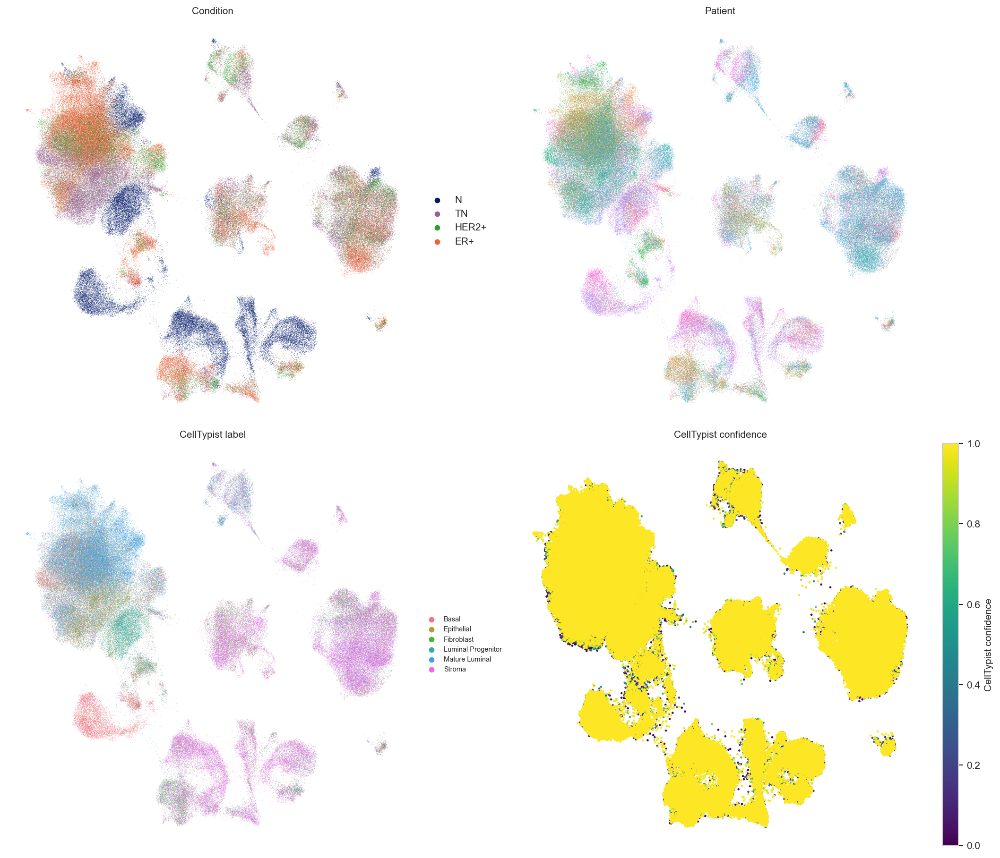

In [31]:
# 002_12: integrated UMAP coloured by condition, patient, CellTypist label and confidence
CELLTYPIST_PALETTE = categorical_palette(
    sorted(adata.obs["celltypist_pal_label"].astype(str).unique()))

fig, axes = plt.subplots(2, 2, figsize=(14, 12), layout="constrained")
ax = axes.ravel()

sc.pl.umap(adata, color="condition", palette=CONDITION_PALETTE, ax=ax[0], show=False,
           frameon=False, legend_loc="right margin", legend_fontsize=10, title="Condition")

# 42 patients: the legend would be unreadable, so the colours are shown without it
sc.pl.umap(adata, color="patient", palette=PATIENT_PALETTE, ax=ax[1], show=False,
           frameon=False, legend_loc=None, title="Patient")

sc.pl.umap(adata, color="celltypist_pal_label", palette=CELLTYPIST_PALETTE, ax=ax[2],
           show=False, frameon=False, legend_loc="right margin", legend_fontsize=7,
           title="CellTypist label")

# continuous confidence (0-1): drawn with matplotlib so the colourbar sits beside the panel
umap = adata.obsm["X_umap"]
confidence = adata.obs["celltypist_pal_conf"].to_numpy()
draw_order = np.argsort(confidence)  # high-confidence cells on top
scatter = ax[3].scatter(umap[draw_order, 0], umap[draw_order, 1], c=confidence[draw_order],
                        s=2, cmap="viridis", vmin=0, vmax=1, rasterized=True)
colourbar = fig.colorbar(scatter, ax=ax[3], fraction=0.046, pad=0.04, aspect=25)
colourbar.set_label("CellTypist confidence")
ax[3].set(title="CellTypist confidence", xticks=[], yticks=[])
ax[3].set_axis_off()

save_figure(fig, "002_12_umap_condition_patient_celltypist")
plt.show()

In [11]:
cl_annotation = {
    # immune
    "0": "T Cells",
    "2": "T Cells",  # proliferating: CORO1A + STMN1/HMGB2
    "1": "T/NK Cells",
    "13": "Macrophages",
    "14": "Macrophages",  # ACP5/CTSK/MMP9/SPP1, osteoclast-like
    "12": "B Cells",
    "24": "Dendritic Cells",  # pDC: LILRA4, IRF7, GZMB, CD1C-negative
    "3": "Plasma Cells",
    "28": "Mast Cells",

    # stromal / vascular
    "15": "Fibroblasts",
    "16": "Fibroblasts",
    "25": "Perivascular",
    "26": "Perivascular",  # metallothionein-high, weak RGS5/PDGFRB
    "17": "Endothelial",
    #"32": "Endothelial: Lymphatic",  # PDPN, ANGPT2, TFPI

    # epithelial
    "10": "Epithelial: Basal",  # KRT14 3.44, KRT5 1.45
    "27": "Epithelial: Basal",
    "20": "Epithelial: Basal",  # + MYLK/ACTA2, myoepithelial
    "11": "Epithelial: Luminal Progenitor",
    #"": "Epithelial: Luminal Progenitor",
    "5": "Epithelial: Mature Luminal",  # GATA3/TFF3/AZGP1/TRPS1
    "21": "Epithelial: Mature Luminal",  # ANKRD30A/AGR2/STC2
    #"8": "Epithelial: Mature Luminal",
    #"19": "Epithelial: Mature Luminal",
    "22": "Epithelial: Mature Luminal",  # ESR1
    "9": "Epithelial: Cycling",  # STMN1/PCLAF/UBE2C
    "18": "Epithelial",  # ERBB2/MIEN1/CDK12/PSMB3 = 17q12 amplicon
    #"6": "Epithelial",  # ERBB2/MIEN1, same amplicon
    "7": "Epithelial",  # ribo 38.1% but KRT19 2.79 - see note
    "19": "Epithelial",
    "29": "Epithelial: Mature Luminal",  # SCGB2A2/SCGB1D2/MUCL1/CRISP3 high; 18.9% MT
    "23": "Epithelial",
    "4": "Epithelial",
    "6": "Epithelial",
    "8": "Epithelial"
}

In [33]:
adata.write_h5ad(adata_dir / "project_integrated_annotated.h5ad", compression="gzip")

In [12]:
adata = sc.read_h5ad(adata_dir / "project_integrated_annotated.h5ad")
adata.obs["condition"] = pd.Categorical(adata.obs["condition"].astype(str),
                                        categories=CONDITION_ORDER, ordered=True)

In [30]:
cross = pd.crosstab(adata.obs["scVI_leiden"], adata.obs["celltypist_pal_label"], normalize="index")
(100 * cross).round(1)

celltypist_pal_label,Basal,Epithelial,Fibroblast,Luminal Progenitor,Mature Luminal,Stroma
scVI_leiden,,,,,,
0,4.4,3.2,21.8,6.0,4.4,60.3
1,4.4,2.7,10.4,3.8,5.3,73.5
2,3.5,3.2,17.7,5.2,5.0,65.4
3,6.8,5.8,18.1,1.4,36.2,31.8
4,19.7,39.0,0.8,14.2,10.6,15.7
5,5.4,24.4,2.3,4.9,56.2,6.8
6,6.7,25.1,2.2,11.6,49.8,4.7
7,13.1,31.8,3.0,14.6,32.1,5.4
8,4.7,52.6,5.7,20.9,13.6,2.4


In [31]:
# cluster composition by CellTypist label: a check, also saved as a supplementary table
composition = pd.crosstab(adata.obs["scVI_leiden"], adata.obs["celltypist_pal_label"],
                          normalize="index")
composition_pct = (100 * composition).round(1)
composition_pct.to_csv(df_dir / "cluster_vs_celltypist_pct.csv")
composition_pct

celltypist_pal_label,Basal,Epithelial,Fibroblast,Luminal Progenitor,Mature Luminal,Stroma
scVI_leiden,,,,,,
0,4.4,3.2,21.8,6.0,4.4,60.3
1,4.4,2.7,10.4,3.8,5.3,73.5
2,3.5,3.2,17.7,5.2,5.0,65.4
3,6.8,5.8,18.1,1.4,36.2,31.8
4,19.7,39.0,0.8,14.2,10.6,15.7
5,5.4,24.4,2.3,4.9,56.2,6.8
6,6.7,25.1,2.2,11.6,49.8,4.7
7,13.1,31.8,3.0,14.6,32.1,5.4
8,4.7,52.6,5.7,20.9,13.6,2.4


In [32]:
print(adata.obs.groupby("scVI_leiden")[["pct_counts_mt", "pct_counts_ribo",
                                        "n_genes_by_counts"]].median().round(1).to_string())

             pct_counts_mt  pct_counts_ribo  n_genes_by_counts
scVI_leiden                                                   
0                 7.300000        26.900000              493.0
1                 8.700000        22.000000              461.0
2                 5.400000        17.100000             1053.5
3                 2.000000         5.700000              651.0
4                10.000000        48.299999             1984.0
5                 6.600000        25.700001             1278.0
6                 3.800000        28.100000             2093.5
7                 6.100000        22.000000             2147.0
8                 4.900000        23.600000             1629.0
9                 3.900000        31.100000              514.0
10               10.100000        26.100000             2700.0
11                4.800000        31.299999             2657.5
12               10.100000        33.299999              491.0
13                5.000000        13.700000            

In [13]:
observed = set(adata.obs["scVI_leiden"].astype(str).unique())
mapped = set(cl_annotation)
assert observed == mapped, (
    f"clusters with no label: {sorted(observed - mapped)}\n"
    f"labels with no cluster: {sorted(mapped - observed)}")
adata.obs["cl_annotation"] = adata.obs["scVI_leiden"].astype(str).map(cl_annotation)
assert adata.obs["cl_annotation"].notna().all()

In [34]:
qc_table = (adata.obs.groupby("scVI_leiden", observed=True)
            .agg(n_cells=("n_genes_by_counts", "size"),
                 cl_annotation=("cl_annotation", "first"),
                 median_pct_mt=("pct_counts_mt", "median"),
                 median_pct_ribo=("pct_counts_ribo", "median"),
                 median_n_genes=("n_genes_by_counts", "median"),
                 median_total_counts=("total_counts", "median"))
            .round(1)
            .sort_values("median_pct_mt", ascending=False))
print(qc_table.to_string())
qc_table.to_csv(df_dir / "cluster_qc_summary.csv")

             n_cells                   cl_annotation  median_pct_mt  median_pct_ribo  median_n_genes  median_total_counts
scVI_leiden                                                                                                              
23               196                      Epithelial      18.700001        11.800000          4106.5              20200.5
29                93      Epithelial: Mature Luminal      11.000000        10.900000          3190.0              10699.0
10               779               Epithelial: Basal      10.100000        26.100000          2700.0              10076.0
12              4885                         B Cells      10.100000        33.299999           491.0               1120.0
4               4526                      Epithelial      10.000000        48.299999          1984.0               9761.0
1              20934                      T/NK Cells       8.700000        22.000000           461.0                865.0
18               941    

In [16]:
# sensitivity analysis: are ROR1+EGFR and EPCAM+ERBB2 co-expressing cells robust to removing
# the low-quality epithelial clusters?
is_epithelial = adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial").to_numpy()
low_quality_clusters = {"4", "23", "29"}  # high ribosomal or MT content, see annotation notes
not_low_quality = ~adata.obs["scVI_leiden"].astype(str).isin(low_quality_clusters).to_numpy()

sensitivity_masks = {
    "all epithelial": is_epithelial,
    "excluding clusters 4, 23 and 29": is_epithelial & not_low_quality,
}

counts = adata.layers["counts"].tocsc()  # column access per gene, no copy of the matrix
gene_index = {g: adata.var_names.get_loc(g) for g in ["ROR1", "EGFR", "EPCAM", "ERBB2"]}

sensitivity_rows = []
for label, mask in sensitivity_masks.items():
    detected = {g: np.asarray(counts[:, j][mask].todense()).ravel() >= 1
                for g, j in gene_index.items()}
    ror1_egfr = detected["ROR1"] & detected["EGFR"]
    epcam_erbb2 = detected["EPCAM"] & detected["ERBB2"]
    sensitivity_rows.append({
        "analysis": label,
        "n_cells": int(mask.sum()),
        "n_ror1_egfr": int(ror1_egfr.sum()),
        "pct_ror1_egfr": round(100 * ror1_egfr.mean(), 2),
        "n_epcam_erbb2": int(epcam_erbb2.sum()),
        "pct_epcam_erbb2": round(100 * epcam_erbb2.mean(), 2),
    })



In [36]:
n_removed = int(adata.obs["scVI_leiden"].astype(str).isin(low_quality_clusters).sum())
print(f"cells in low-quality clusters: {n_removed:,}")
assert n_removed > 0, f"none of {sorted(low_quality_clusters)} present in scVI_leiden"

cells in low-quality clusters: 4,815


In [37]:
summary = (adata.obs.groupby("cl_annotation")["celltypist_pal_conf"]
           .agg(["count", "median"]).round(2)
           .sort_values("median"))
print(summary.to_string())

                                count  median
cl_annotation                                
Plasma Cells                     7101    0.82
Epithelial: Cycling              6472    0.88
Epithelial                      37671    0.92
Epithelial: Luminal Progenitor  12416    0.99
Epithelial: Mature Luminal      57820    0.99
Mast Cells                        883    0.99
B Cells                          4885    1.00
Dendritic Cells                   665    1.00
Endothelial                      9388    1.00
Epithelial: Basal               14686    1.00
Fibroblasts                     20926    1.00
Macrophages                     16932    1.00
Perivascular                     6462    1.00
T Cells                         20540    1.00
T/NK Cells                      20934    1.00


In [38]:
# epithelial clusters by CellTypist label
cross_epi = pd.crosstab(adata.obs.loc[is_epithelial, "scVI_leiden"],
                        adata.obs.loc[is_epithelial, "celltypist_pal_label"], normalize="index")
(100 * cross_epi).round(1)

celltypist_pal_label,Basal,Epithelial,Fibroblast,Luminal Progenitor,Mature Luminal,Stroma
scVI_leiden,,,,,,
4,19.7,39.0,0.8,14.2,10.6,15.7
5,5.4,24.4,2.3,4.9,56.2,6.8
6,6.7,25.1,2.2,11.6,49.8,4.7
7,13.1,31.8,3.0,14.6,32.1,5.4
8,4.7,52.6,5.7,20.9,13.6,2.4
9,12.0,22.0,9.2,11.9,33.2,11.7
10,6.8,19.5,1.9,9.0,55.7,7.1
11,2.5,21.6,0.7,67.6,6.4,1.3
18,11.7,14.8,0.2,4.3,63.0,6.1


In [39]:
# all clusters, with low-confidence calls (probability <= 0.5) grouped separately
confident = adata.obs["celltypist_pal_conf"] > 0.5
cross_conf = pd.crosstab(adata.obs["scVI_leiden"],
                         adata.obs["celltypist_pal_label"].astype(str).where(confident, "low confidence"))
(100 * cross_conf.div(cross_conf.sum(axis=1), axis=0)).round(1)

celltypist_pal_label,Basal,Epithelial,Fibroblast,Luminal Progenitor,Mature Luminal,Stroma,low confidence
scVI_leiden,,,,,,,
0,3.1,1.4,18.6,4.9,3.3,55.5,13.2
1,3.2,1.2,8.6,3.2,4.0,69.1,10.6
2,2.3,1.1,14.3,4.4,3.9,59.7,14.3
3,3.1,1.5,10.5,0.8,24.1,20.6,39.3
4,14.5,21.5,0.5,9.6,6.6,12.9,34.4
5,3.8,13.1,1.5,3.6,48.4,5.1,24.5
6,3.6,7.0,1.4,6.8,39.9,2.2,39.1
7,7.7,10.1,1.6,8.7,23.2,3.3,45.4
8,2.2,20.2,3.1,13.0,7.5,1.1,53.0


In [40]:
(adata.obs.groupby("scVI_leiden")["celltypist_pal_conf"]
 .apply(lambda x: (x < 0.5).mean() * 100).round(1)
 .sort_values(ascending=False).head(12))

scVI_leiden
8     53.0
22    51.1
7     45.4
10    41.2
3     39.3
6     39.1
9     36.8
4     34.4
18    33.2
14    32.8
28    31.3
20    30.9
Name: celltypist_pal_conf, dtype: float64

... storing 'cl_annotation' as categorical


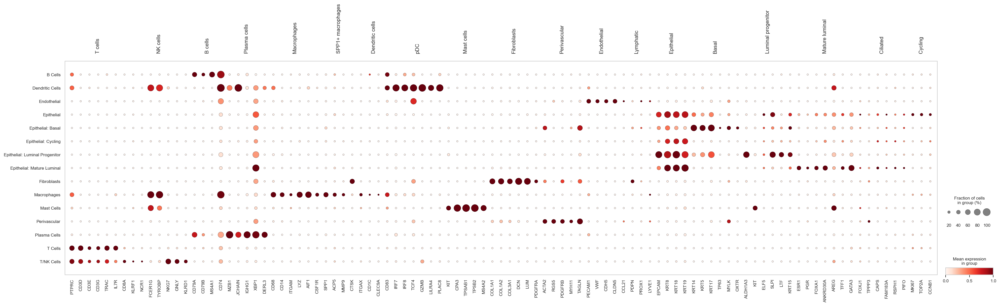

In [19]:
# 002_13: marker dotplot grouped by annotated cell type (same marker set as 002_09)
n_genes = sum(len(genes) for genes in present.values())
n_types = adata.obs["cl_annotation"].nunique()
fig, ax = plt.subplots(figsize=(0.28 * n_genes + 4, 0.45 * n_types + 2), layout="constrained")
sc.pl.dotplot(adata, groupby="cl_annotation", var_names=present, layer="log1p",
              standard_scale="var", dendrogram=False, smallest_dot=10, ax=ax, show=False)
save_figure(fig, "002_13_dotplot_markers_by_celltype")
plt.show()

In [20]:
is_epithelial = adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial").to_numpy()
epi_idx = np.flatnonzero(is_epithelial)
epcam_col = adata.var_names.get_loc("EPCAM")
epcam = adata.layers["log1p"][epi_idx, epcam_col].toarray().ravel()
print(f"EPCAM detected in {100 * (epcam > 0).mean():.1f}% of the epithelial subset")

EPCAM detected in 48.1% of the epithelial subset


# Saving Epithelial Compartment

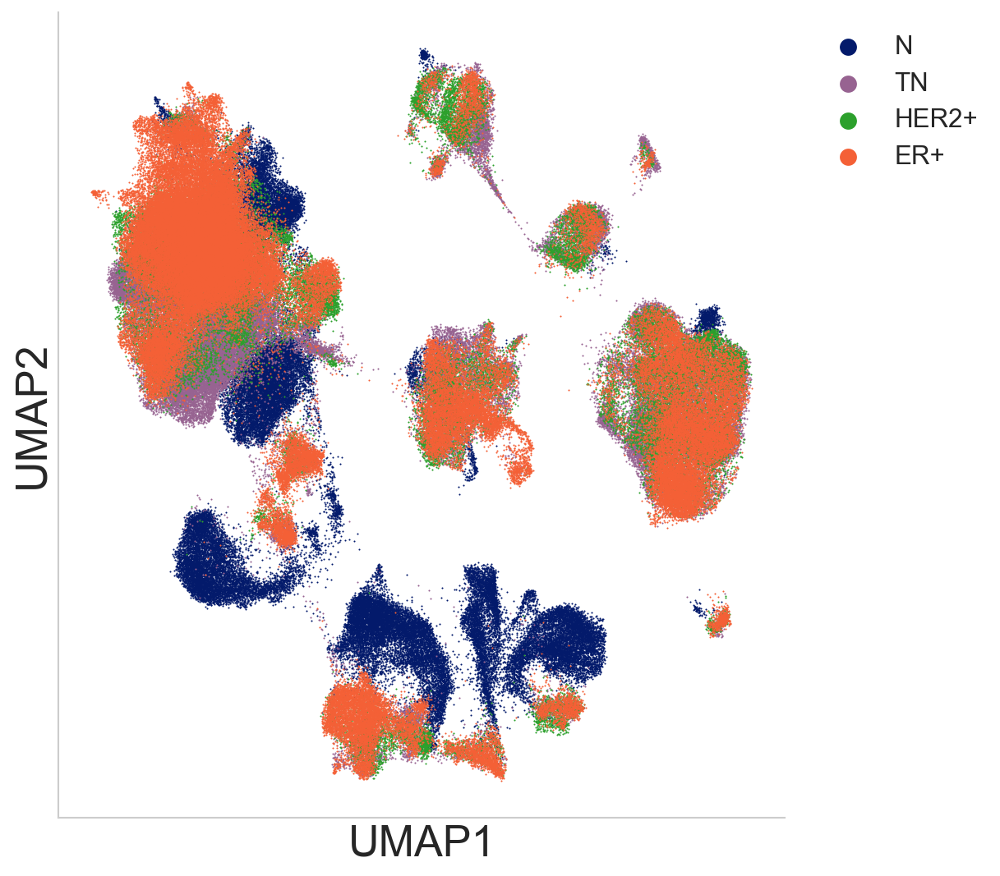

In [21]:
# First = bottom layer, last = top layer
plot_order = ["N", "TN", "HER2+", "ER+"]

cond = adata.obs["condition"].astype(str)
unexpected = set(cond.unique()) - set(plot_order)
assert not unexpected, f"Unexpected condition labels: {unexpected}"

umap = adata.obsm["X_umap"]

fig, ax = plt.subplots(figsize=(8, 7), layout="constrained")
for c in plot_order:   # drawn in this order: later groups sit on top
    m = (cond == c).to_numpy()
    if m.any():
        ax.scatter(umap[m, 0], umap[m, 1], s=1, color=CONDITION_PALETTE[c],
                   label=c, linewidths=0, rasterized=True)

ax.set_xlabel("UMAP1", fontsize=25)
ax.set_ylabel("UMAP2", fontsize=25)
ax.set_xticks([])
ax.set_yticks([])
ax.tick_params(axis="both", labelsize=12)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

legend = ax.legend(markerscale=10, fontsize=15, frameon=False,
                   bbox_to_anchor=(1.02, 1), loc="upper left")

save_figure(fig, "umap_condition")
plt.show()
plt.close(fig)

In [22]:
#saving cell barcodes with metadata to CSV
adata.obs[["sample", "condition", "patient", "cl_annotation", "scVI_leiden"]].to_csv(
    df_dir / "cell_metadata.csv")


In [23]:
missing = set(adata.obs["cl_annotation"].astype(str).unique()) - set(CELLTYPE_PALETTE)
assert not missing, f"palette missing: {missing}"
print(f"palette covers all {adata.obs['cl_annotation'].nunique()} labels")

palette covers all 15 labels


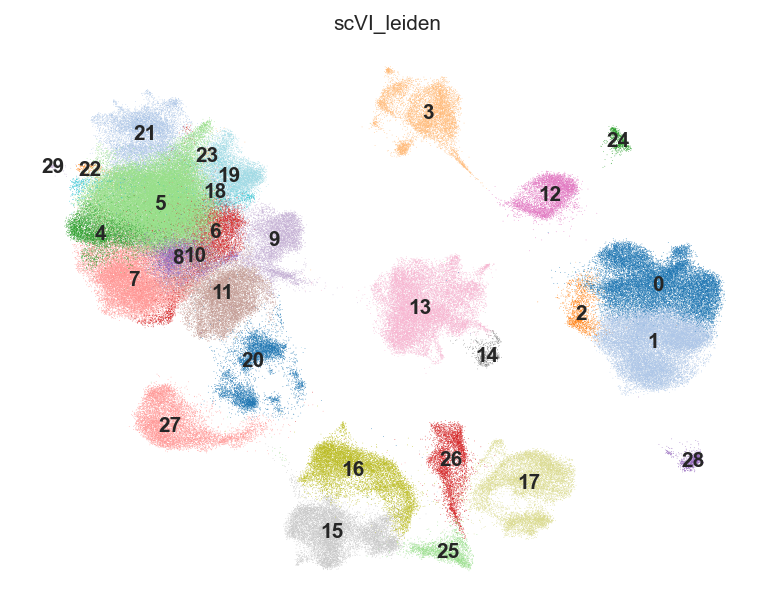

In [24]:
sc.pl.umap(adata, color='scVI_leiden', legend_loc='on data', palette=sns.color_palette("tab20", n_colors=adata.obs['scVI_leiden'].nunique()), frameon=False, show=False)

save_figure(fig, "umap_leiden_final")
plt.show()


[PosixPath('/Volumes/TOSHIBA EXT/IdeaProjects/Nowotny_publication/results/figures/8_Celltypes_N2.png'),
 PosixPath('/Volumes/TOSHIBA EXT/IdeaProjects/Nowotny_publication/results/figures/8_Celltypes_N2.svg')]

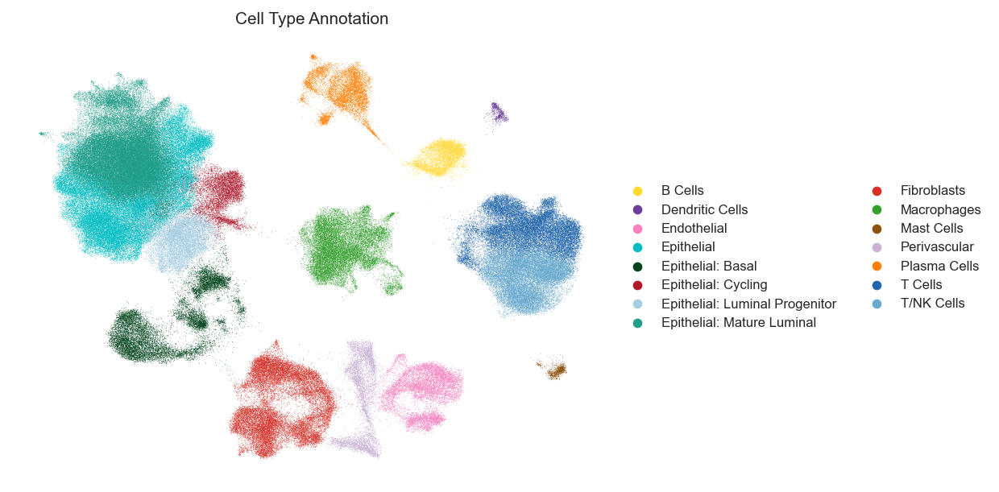

In [25]:
#6 UMAP coloured by Celltype
sc.pl.umap(adata, color="cl_annotation", palette=CELLTYPE_PALETTE, layer="log1p", legend_loc="right margin", legend_fontsize=8, title="Cell Type Annotation", frameon=False, show=False)
save_figure(fig, "8_Celltypes_N2")

In [26]:
import gc
gc.collect()

26569

In [27]:
# Map clusters to cell-type annotation
assert adata.obs["cl_annotation"].notna().all()

# Extract epithelial cells across all conditions
epithelial_mask = (
    adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial")
)

epithelial_obs = adata.obs.loc[
    epithelial_mask, ["sample", "condition", "cl_annotation", "scVI_leiden"]].copy()

# Summary
print(f"Epithelial cells: {epithelial_mask.sum():,}")
print("\nCell types:")
print(epithelial_obs["cl_annotation"].value_counts())
print("\nConditions:")
print(epithelial_obs["condition"].value_counts())
print("\nSamples:")
print(epithelial_obs["sample"].value_counts())
# print("\nPatients:") print(epithelial_obs["patient"].value_counts())

# Saving barcodes
epithelial_obs.to_csv(df_dir / "epithelial_barcodes.csv", index=True, index_label="barcode")

Epithelial cells: 129,065

Cell types:
cl_annotation
Epithelial: Mature Luminal        57820
Epithelial                        37671
Epithelial: Basal                 14686
Epithelial: Luminal Progenitor    12416
Epithelial: Cycling                6472
B Cells                               0
Dendritic Cells                       0
Endothelial                           0
Fibroblasts                           0
Macrophages                           0
Mast Cells                            0
Perivascular                          0
Plasma Cells                          0
T Cells                               0
T/NK Cells                            0
Name: count, dtype: int64

Conditions:
condition
ER+      59945
TN       26360
N        26334
HER2+    16426
Name: count, dtype: int64

Samples:
sample
GSM4909282_TN-MH0135         12122
GSM4909306_ER-MH0029-9C       5809
GSM4909299_ER-MH0114-T3       5808
GSM4909297_ER-MH0125          5430
GSM4909296_ER-MH0001          5048
GSM4909304_ER-MH0163

In [28]:
(pd.crosstab(adata.obs["scVI_leiden"], adata.obs["celltypist_pal_label"])
   .to_csv(df_dir / "cluster_vs_celltypist.csv"))

In [29]:
#Saving Table for Barplot (Celltype Distribution per Sample)
barcode_df = adata.obs[["sample", "condition", "patient", "cl_annotation"]].copy()
barcode_df.index.name = "barcode"
barcode_df.to_csv(df_dir / "barcode_table.csv")

### Supplementary Figure 1b, 1c, 1e

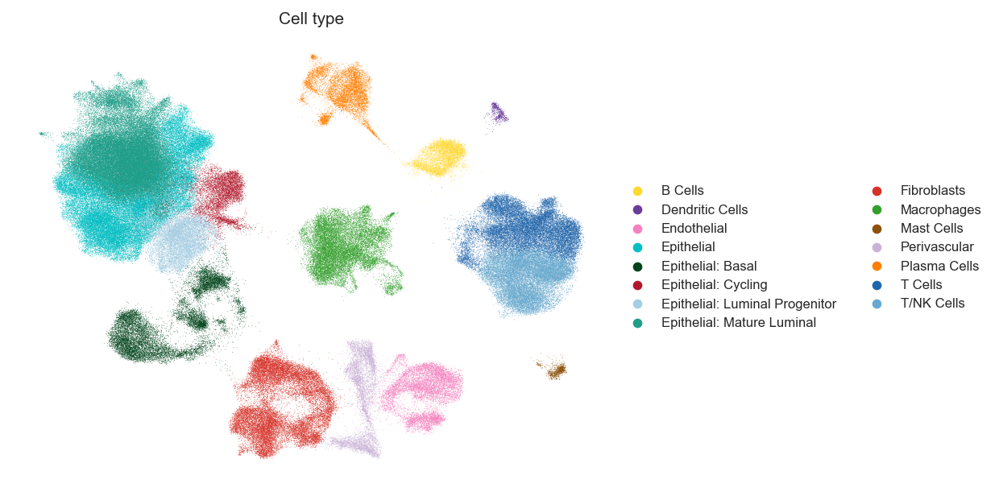

In [30]:
# Supplementary Figure 1b - cell types on the atlas UMAP
sc.pl.umap(adata, color="cl_annotation", palette=CELLTYPE_PALETTE,
           legend_loc="right margin", legend_fontsize=8, frameon=False,
           title="Cell type", show=False)
save_figure(fig, "supp1b_celltypes")
plt.show()

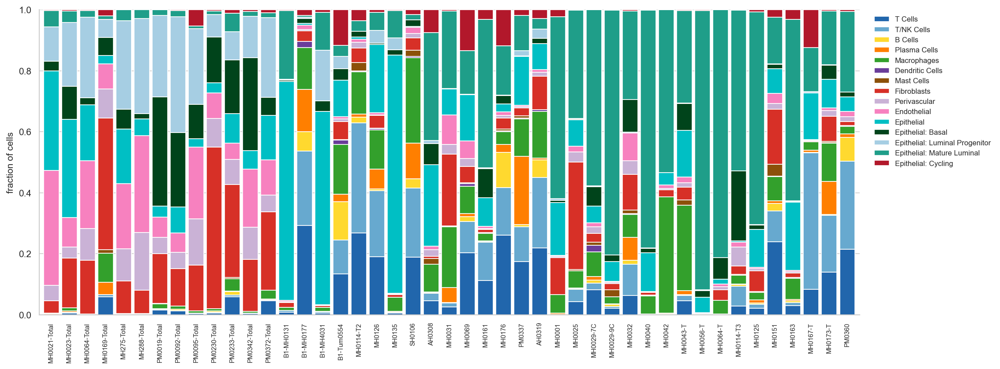

In [31]:
#  cell-type composition of every sample, samples grouped by condition
comp = pd.crosstab(adata.obs["sample_short"], adata.obs["cl_annotation"], normalize="index")

order = (adata.obs[["sample_short", "condition"]].drop_duplicates()
         .assign(rank=lambda d: d["condition"].map({"N": 0, "TN": 1, "HER2+": 2, "ER+": 3}))
         .sort_values(["rank", "sample_short"])["sample_short"])

comp = comp.loc[order]
cols = [c for c in CELLTYPE_PALETTE if c in comp.columns] + \
       [c for c in comp.columns if c not in CELLTYPE_PALETTE]
comp = comp[cols]

fig, ax = plt.subplots(figsize=(16, 6))
comp.plot(kind="bar", stacked=True, width=0.85, ax=ax,
          color=[CELLTYPE_PALETTE.get(c, "lightgrey") for c in comp.columns])

ax.set_xlabel("")
ax.set_ylabel("fraction of cells")
ax.set_ylim(0, 1)
ax.tick_params(axis="x", labelsize=7, rotation=90)
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
save_figure(fig, "supp1c_celltype_per_sample")
plt.show()

comp.to_csv(df_dir / "celltype_fraction_per_sample.csv")

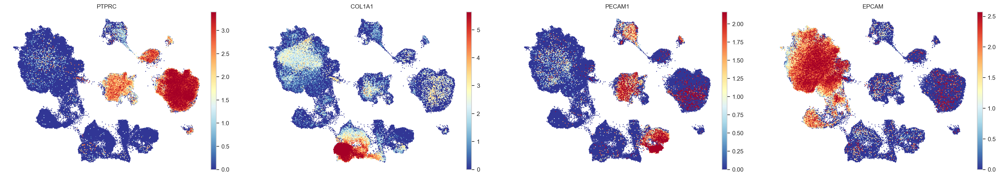

In [32]:
# Supplementary Figure 1e - lineage markers on the atlas UMAP
sc.pl.umap(adata, color=["PTPRC", "COL1A1", "PECAM1", "EPCAM"], ncols=4,
           layer="log1p", cmap="RdYlBu_r", vmin=0, vmax="p99", size=8,
           frameon=False, show=False)
save_figure(fig, "supp1e_marker_umaps")
plt.show()

In [33]:
genes_present = [g for g in sorted({g for v in marker_genes.values() for g in v})
                 if g in adata.var_names]

In [34]:
#Saving Table for PieChart (Epithelial Cells per Sample/Condition)
adata_sub = adata[:, genes_present].copy()
X = adata_sub.layers["log1p"]

df = pd.DataFrame(
    X.toarray() if hasattr(X, "toarray") else X,
    index=adata_sub.obs_names,
    columns=genes_present
)

#adding metadata
df["cluster"] = adata_sub.obs["scVI_leiden"].values
df["cell_type"] = adata_sub.obs["cl_annotation"].values

df.index.name = "barcode"
tmp = df.reset_index()
#Table for Dotplot (Celltype Markers)
long_df = tmp.melt(
    id_vars=["barcode", "cluster", "cell_type"],
    var_name="gene",
    value_name="expression"
)


long_df.to_csv(df_dir / "dotplot_long_format.csv", index=False)

In [35]:
# free the large intermediates; nothing below uses them
del adata_sub
gc.collect()

16529

In [36]:
print(df.index.name)
print(df.columns.tolist())

barcode
['ACP5', 'ACTA2', 'AIF1', 'ALDH1A3', 'ANKRD30A', 'AREG', 'CAPS', 'CCL21', 'CCNB1', 'CD14', 'CD1C', 'CD3D', 'CD3E', 'CD3G', 'CD68', 'CD74', 'CD79A', 'CD79B', 'CD83', 'CD8A', 'CDH5', 'CLDN5', 'CLEC9A', 'COL1A1', 'COL1A2', 'COL3A1', 'CPA3', 'CSF1R', 'CTSK', 'DCN', 'DERL3', 'ELF5', 'EPCAM', 'ESR1', 'FAM183A', 'FCER1G', 'FOXA1', 'FOXJ1', 'GATA3', 'GNLY', 'GZMB', 'IGHG1', 'IL7R', 'IRF7', 'IRF8', 'ITGAM', 'ITGAX', 'JCHAIN', 'KIT', 'KLRD1', 'KLRF1', 'KRT14', 'KRT15', 'KRT17', 'KRT18', 'KRT19', 'KRT5', 'KRT8', 'LILRA4', 'LTF', 'LUM', 'LYVE1', 'LYZ', 'MKI67', 'MMP9', 'MS4A1', 'MS4A2', 'MYH11', 'MYLK', 'MZB1', 'NCR1', 'NKG7', 'OXTR', 'PDGFRA', 'PDGFRB', 'PDPN', 'PECAM1', 'PGR', 'PIFO', 'PLAC8', 'PROX1', 'PTPRC', 'RGS5', 'RSPH1', 'SLPI', 'SPP1', 'TAGLN', 'TCF4', 'TFF1', 'TOP2A', 'TP63', 'TPPP3', 'TPSAB1', 'TPSB2', 'TRAC', 'TYROBP', 'VWF', 'XBP1', 'cluster', 'cell_type']


In [ ]:
full_path = adata_dir / "project_integrated_annotated.h5ad"
adata_b = ad.read_h5ad(full_path, backed="r")  # matrix stays on disk

In [37]:
full_path = adata_dir / "project_integrated_annotated.h5ad"
adata_b = ad.read_h5ad(full_path, backed="r")  # matrix stays on disk

epi_mask = adata_b.obs["cl_annotation"].astype(str).str.startswith("Epithelial").values
idx = np.where(epi_mask)[0]
print("cells selected:", len(idx), "of", adata_b.n_obs)

epi = adata_b[idx].to_memory()
adata_b.file.close()

epi.obs["condition"] = pd.Categorical(epi.obs["condition"].astype(str),
                                      categories=CONDITION_ORDER, ordered=True)

epi.write_h5ad(adata_dir / "epithelial.h5ad")
print("epithelial:", epi.shape)

KeyError: 'cl_annotation'

### Supplementary Figure 1g

In [ ]:
# Supplementary Figure 1g - which samples contribute the epithelial cohort. Inner ring is the clinical condition, outer ring the individual samples.
contrib = (epi.obs.groupby(["condition", "sample_short"], observed=True)
           .size().rename("cells").reset_index())

contrib["rank"] = contrib["condition"].map(condition_rank)
contrib = contrib.sort_values(["rank", "cells"], ascending=[True, False])

inner = contrib.groupby("condition", observed=True)["cells"].sum().reindex(
    [c for c in CONDITION_ORDER if c in set(contrib["condition"])])

inner_colors = [CONDITION_PALETTE.get(c, CONDITION_PALETTE.get(c.rstrip("+"), "lightgrey"))
                for c in inner.index]
outer_colors = []
for c, col in zip(inner.index, inner_colors):
    n = int((contrib["condition"] == c).sum())
    outer_colors += [to_rgba(col, alpha=a) for a in np.linspace(0.95, 0.35, n)]

fig, ax = plt.subplots(figsize=(9, 9))

ax.pie(inner.values, radius=0.72, colors=inner_colors,
       labels=inner.index, labeldistance=0.45,
       wedgeprops=dict(width=0.42, edgecolor="white", linewidth=1),
       textprops=dict(fontsize=11, weight="bold", color="white"))

ax.pie(contrib["cells"].values, radius=1.0, colors=outer_colors,
       labels=contrib["sample_short"], labeldistance=1.03, rotatelabels=True,
       wedgeprops=dict(width=0.28, edgecolor="white", linewidth=0.6),
       textprops=dict(fontsize=6))

ax.set(aspect="equal")
ax.text(0, 0, f"{epi.n_obs:,}\nepithelial cells\n{epi.obs['patient'].nunique()} patients",
        ha="center", va="center", fontsize=11)
save_figure(fig, "supp1g_epithelial_contribution")
plt.show()

contrib.to_csv(df_dir / "epithelial_contribution_per_sample.csv", index=False)

In [ ]:
epi_mask = adata.obs["cl_annotation"].astype(str).str.startswith("Epithelial")
x = np.asarray(adata[:, "EPCAM"].layers["log1p"].todense()).ravel() > 0
print(f"EPCAM+ inside  epithelial : {100*x[epi_mask].mean():.1f}%")
print(f"EPCAM+ outside epithelial : {100*x[~epi_mask].mean():.1f}%")


In [ ]:
conn  = adata.obsp["connectivities"].tocsr()
codes = adata.obs["sample"].astype("category").cat.codes.to_numpy()
same  = (codes[conn.indices] == np.repeat(codes, np.diff(conn.indptr)))
adata.obs["frac_same_sample"] = np.add.reduceat(same, conn.indptr[:-1]) / np.maximum(np.diff(conn.indptr), 1)

p = adata.obs["sample"].value_counts(normalize=True).to_numpy()
print(f"expected if perfectly mixed: {(p**2).sum():.3f}\n")
print(adata.obs.groupby("cl_annotation")["frac_same_sample"].median().round(3).sort_values().to_string())


In [ ]:
import session_info

session_info.show()